# [3rd Place Efficiency Prize] Simple Solution

## 1. Project Overview and Original Kaggle Submission

**Competition:** LLM - Detect AI Generated Text  
**Placement:** 3rd Place Efficiency Prize  
**Author attribution:** The Kaggle page title and placement are visible, but its public page response did not expose an author name. No author attribution is inferred here.  
**Original submission:** [\[3rd Place Efficiency Prize\] Simple Solution](https://www.kaggle.com/competitions/llm-detect-ai-generated-text/writeups/beat-tfidf-3rd-place-efficiency-prize-simple-solut)

The original write-up's article body, author-linked notebooks/source, and fitted artifacts were not accessible for independent inspection when this notebook was prepared. The BPE + 3–4-gram TF-IDF + SGD + CatBoost + weighted-voting description comes from project research notes and remains **unverified**. This notebook is therefore a documented, leakage-aware adaptation—not a claim of exact reproduction. See [reproduction notes](references/submission3_reproduction_notes.md).

The notebook defaults to the explicit `low_memory` profile. The `original` profile is intentionally blocked until its published hyperparameters can be verified; the Kaggle page currently exposes only a client-side shell. This avoids presenting guessed settings as an original reproduction.

**Task labels:** `0` = human-written; `1` = AI-generated. **Primary metric:** ROC-AUC.


In [ ]:
from pathlib import Path
import os
import sys

from google.colab import drive

drive.mount("/content/drive")
PROJECT_ROOT = Path("/content/drive/MyDrive/DeepLearning_progress")
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Google Drive project folder not found: {PROJECT_ROOT}")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

if not (PROJECT_ROOT / "requirements.txt").is_file():
    raise FileNotFoundError(f"requirements.txt not found in {PROJECT_ROOT}")
%pip install -r requirements.txt

## 2. Reproduction Objectives

This experiment uses the team's combined essay dataset, a deterministic 80/10/10 stratified split (seed 747), and identical held-out records for each classifier. Normalized duplicate essays are handled before splitting. BPE, TF-IDF, and classifiers are fitted on training records only; validation selects the ensemble mixture; the test set is held for final evaluation.

Published Submission #3 hyperparameters cannot be confirmed from the accessible write-up. All implementation choices marked **adaptation** are project defaults, not source-verified settings.


## 3. Dependencies and Configuration

The first code cell mounts Google Drive and uses `MyDrive/DeepLearning_progress` as the project folder. Keep `requirements.txt`, `cs747_submission3.py`, and the `data` folder there; the dataset is expected at `data/CS747data.csv`. Per-mode artifacts and checkpoints are saved under `outputs/<mode>/`; the shared split manifests for this ratio remain under `outputs/dataset_splits/seed_747_train_80_val_10_test_10/`. Checkpoint keys include mode, dataset and split fingerprints, preprocessing/classifier settings, helper-module content, and relevant library versions. Rerun cells from the top to reuse compatible checkpoints. TF-IDF sparse-matrix checkpoints can use substantial Drive storage.

This notebook uses a memory-conservative adaptation: TF-IDF is capped at 25,000 features, and CatBoost uses depth 4, 100 iterations, and at most two CPU threads. These settings may change ROC-AUC from the earlier configuration. The optional Logistic Regression comparison is disabled by default.


In [ ]:
from pathlib import Path
import hashlib
import gc
import json
import os
import platform
import resource
import sys
import time
import unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import scipy
import sklearn
from catboost import CatBoostClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from scipy.sparse import load_npz, save_npz
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers

from cs747_submission3 import BPEWordTokenizer

for variable_name in (
    "raw_df", "audit_df", "eligible", "provenance", "model_df",
    "train_df", "val_df", "test_df", "rest_df", "split_sets",
    "X_train", "X_val", "X_test", "X_benchmark", "vectorizer",
    "raw_tokenizer", "bpe_word_tokenizer", "cat_model", "sgd_model", "logreg_model",
    "test_error_table", "false_positives", "false_negatives", "benchmark_texts",
    "test_probabilities", "validation_probabilities",
):
    globals().pop(variable_name, None)
gc.collect()

SEED = 747
TRAIN_FRACTION = 0.80
VALIDATION_FRACTION = 0.10
TEST_FRACTION = 0.10
CONFIG_MODE = "low_memory"  # Choose "low_memory" or "original".

CONFIG_PROFILES = {
    "low_memory": {
        "status": "ready; adaptation settings, not verified original parameters",
        "settings": {
            "bpe_vocab_size": 16000,
            "bpe_unk_token": "[UNK]",
            "bpe_normalizer": "NFC",
            "bpe_pre_tokenizer": "ByteLevel",
            "bpe_add_prefix_space": False,
            "bpe_special_tokens": ["[UNK]"],
            "tfidf_ngram_range": (3, 4),
            "tfidf_min_df": 3,
            "tfidf_max_features": 25000,
            "tfidf_lowercase": False,
            "tfidf_strip_accents": "unicode",
            "tfidf_sublinear_tf": True,
            "tfidf_dtype": "float32",
            "tfidf_analyzer": "word",
            "sgd_settings": {
                "loss": "modified_huber",
                "penalty": "l2",
                "alpha": 1e-4,
                "max_iter": 5000,
                "tol": 1e-4,
                "random_state": SEED,
            },
            "catboost_settings": {
                "iterations": 100,
                "depth": 4,
                "border_count": 32,
                "learning_rate": 0.1,
                "loss_function": "Logloss",
                "eval_metric": "AUC",
                "random_seed": SEED,
                "thread_count": 2,
                "verbose": False,
                "allow_writing_files": True,
            },
            "benchmark_max_rows": 2000,
            "benchmark_repeats": 5,
            "ensemble_weight_step": 0.05,
            "decision_threshold": 0.5,
        },
    },
    "original": {
        "status": "blocked: original hyperparameters were not accessible for verification",
        "settings": None,
        "reason": (
            "The Kaggle write-up response contains only its client-side shell. "
            "Supply verified original values in this profile before selecting original; "
            "the notebook will not guess or silently substitute low-memory settings."
        ),
    },
}

EVALUATION_PROTOCOL = {
    "benchmark_max_rows": CONFIG_PROFILES["low_memory"]["settings"]["benchmark_max_rows"],
    "benchmark_repeats": CONFIG_PROFILES["low_memory"]["settings"]["benchmark_repeats"],
    "ensemble_weight_step": CONFIG_PROFILES["low_memory"]["settings"]["ensemble_weight_step"],
    "decision_threshold": CONFIG_PROFILES["low_memory"]["settings"]["decision_threshold"],
}

if not isinstance(EVALUATION_PROTOCOL["benchmark_max_rows"], int) or EVALUATION_PROTOCOL["benchmark_max_rows"] <= 0:
    raise ValueError("benchmark_max_rows must be a positive integer.")
if not isinstance(EVALUATION_PROTOCOL["benchmark_repeats"], int) or EVALUATION_PROTOCOL["benchmark_repeats"] < 5:
    raise ValueError("benchmark_repeats must be at least five for comparable timings.")
weight_step = EVALUATION_PROTOCOL["ensemble_weight_step"]
if not isinstance(weight_step, (int, float)) or not np.isfinite(weight_step) or weight_step <= 0 or round(1 / weight_step) != 1 / weight_step:
    raise ValueError("ensemble_weight_step must be a positive finite step that divides 1 exactly.")
threshold = EVALUATION_PROTOCOL["decision_threshold"]
if not isinstance(threshold, (int, float)) or not np.isfinite(threshold) or not 0 <= threshold <= 1:
    raise ValueError("decision_threshold must be a finite value between 0 and 1.")

def profile_table_row(mode):
    profile = CONFIG_PROFILES[mode]
    settings = profile.get("settings") or {}
    catboost = settings.get("catboost_settings", {})
    status = profile["status"] if profile.get("settings") is None else "settings supplied; verify source provenance"
    return {
        "mode": mode,
        "status": status,
        "BPE vocab / normalizer / pre-tokenizer": (
            f"{settings.get('bpe_vocab_size', 'unknown')} / "
            f"{settings.get('bpe_normalizer', 'unknown')} / "
            f"{settings.get('bpe_pre_tokenizer', 'unknown')}"
        ),
        "TF-IDF n-grams / min_df / max_features / dtype": (
            f"{settings.get('tfidf_ngram_range', 'unknown')} / "
            f"{settings.get('tfidf_min_df', 'unknown')} / "
            f"{settings.get('tfidf_max_features', 'unknown')} / "
            f"{settings.get('tfidf_dtype', 'unknown')}"
        ),
        "SGD": json.dumps(settings.get("sgd_settings", "unknown"), sort_keys=True),
        "CatBoost iterations / depth / border_count / learning_rate / threads": (
            f"{catboost.get('iterations', 'unknown')} / {catboost.get('depth', 'unknown')} / "
            f"{catboost.get('border_count', 'unknown')} / {catboost.get('learning_rate', 'unknown')} / "
            f"{catboost.get('thread_count', 'unknown')}"
        ),
        "Benchmark rows / repeats": (
            f"{EVALUATION_PROTOCOL['benchmark_max_rows']} / {EVALUATION_PROTOCOL['benchmark_repeats']}"
        ),
        "Ensemble weight step / threshold": (
            f"{EVALUATION_PROTOCOL['ensemble_weight_step']} / {EVALUATION_PROTOCOL['decision_threshold']}"
        ),
    }

profile_table = pd.DataFrame([profile_table_row("low_memory"), profile_table_row("original")]).set_index("mode")
print(f"Selected CONFIG_MODE: {CONFIG_MODE}")
display(profile_table)

if CONFIG_MODE not in CONFIG_PROFILES:
    raise ValueError(f"Unsupported CONFIG_MODE={CONFIG_MODE!r}; choose one of {tuple(CONFIG_PROFILES)}.")
selected_profile = CONFIG_PROFILES[CONFIG_MODE]
if CONFIG_MODE == "original":
    if selected_profile.get("settings") is None:
        raise RuntimeError(selected_profile["reason"])
    CONFIG = selected_profile["settings"]
    CONFIG_STATUS = "user-supplied original settings; verify against primary source"
else:
    CONFIG = selected_profile["settings"]
    CONFIG_STATUS = selected_profile["status"]
required_config_keys = {
    "bpe_vocab_size", "bpe_unk_token", "bpe_normalizer", "bpe_pre_tokenizer", "bpe_add_prefix_space", "bpe_special_tokens",
    "tfidf_ngram_range", "tfidf_min_df", "tfidf_max_features", "tfidf_lowercase",
    "tfidf_strip_accents", "tfidf_sublinear_tf", "tfidf_dtype", "tfidf_analyzer",
    "sgd_settings", "catboost_settings",
}
missing_config_keys = required_config_keys.difference(CONFIG)
if missing_config_keys:
    raise ValueError(f"The {CONFIG_MODE!r} configuration is missing: {sorted(missing_config_keys)}")
if not isinstance(CONFIG["bpe_vocab_size"], int) or CONFIG["bpe_vocab_size"] <= 0:
    raise ValueError("bpe_vocab_size must be a positive integer.")
if not isinstance(CONFIG["bpe_special_tokens"], list) or not all(
    isinstance(token, str) for token in CONFIG["bpe_special_tokens"]
):
    raise ValueError("bpe_special_tokens must be a list of strings.")
if CONFIG["bpe_unk_token"] is not None and not isinstance(CONFIG["bpe_unk_token"], str):
    raise ValueError("bpe_unk_token must be a string or None.")
if CONFIG["bpe_unk_token"] is not None and CONFIG["bpe_unk_token"] not in CONFIG["bpe_special_tokens"]:
    raise ValueError("bpe_unk_token must be included in bpe_special_tokens.")
if CONFIG["bpe_normalizer"] not in {None, "NFC", "NFKC"}:
    raise ValueError("Supported BPE normalizers are None, NFC, and NFKC.")
if CONFIG["bpe_pre_tokenizer"] not in {"ByteLevel", "Whitespace", "WhitespaceSplit"}:
    raise ValueError("Supported BPE pre-tokenizers are ByteLevel, Whitespace, and WhitespaceSplit.")
if not isinstance(CONFIG["bpe_add_prefix_space"], bool):
    raise ValueError("bpe_add_prefix_space must be a boolean.")
ngram_range = CONFIG["tfidf_ngram_range"]
if (
    not isinstance(ngram_range, (tuple, list))
    or len(ngram_range) != 2
    or not all(isinstance(value, int) and value > 0 for value in ngram_range)
    or ngram_range[0] > ngram_range[1]
):
    raise ValueError("tfidf_ngram_range must contain two positive, ordered integers.")
min_df = CONFIG["tfidf_min_df"]
if not isinstance(min_df, (int, float)) or not np.isfinite(min_df) or min_df <= 0 or (isinstance(min_df, float) and min_df >= 1):
    raise ValueError("tfidf_min_df must be a positive integer or a fraction below 1.")
max_features = CONFIG["tfidf_max_features"]
if max_features is not None and (not isinstance(max_features, int) or max_features <= 0):
    raise ValueError("tfidf_max_features must be a positive integer or None.")
if not isinstance(CONFIG["tfidf_lowercase"], bool) or not isinstance(CONFIG["tfidf_sublinear_tf"], bool):
    raise ValueError("tfidf_lowercase and tfidf_sublinear_tf must be booleans.")
if CONFIG["tfidf_strip_accents"] not in {None, "ascii", "unicode"}:
    raise ValueError("tfidf_strip_accents must be None, 'ascii', or 'unicode'.")
if CONFIG["tfidf_dtype"] not in {"float32", "float64"} or CONFIG["tfidf_analyzer"] != "word":
    raise ValueError("tfidf_dtype must be float32/float64 and tfidf_analyzer must be 'word'.")
if not isinstance(CONFIG["sgd_settings"], dict) or not CONFIG["sgd_settings"] or not isinstance(CONFIG["catboost_settings"], dict):
    raise ValueError("sgd_settings must be a non-empty dictionary and catboost_settings must be a dictionary.")
required_sgd_keys = {"loss", "penalty", "alpha", "max_iter", "tol", "random_state"}
missing_sgd_keys = required_sgd_keys.difference(CONFIG["sgd_settings"])
if missing_sgd_keys:
    raise ValueError(f"sgd_settings is missing: {sorted(missing_sgd_keys)}")
required_catboost_keys = {"iterations", "depth", "border_count", "learning_rate", "thread_count"}
missing_catboost_keys = required_catboost_keys.difference(CONFIG["catboost_settings"])
if missing_catboost_keys:
    raise ValueError(f"catboost_settings is missing: {sorted(missing_catboost_keys)}")
for integer_key in ("iterations", "depth", "border_count", "thread_count"):
    if not isinstance(CONFIG["catboost_settings"][integer_key], int) or CONFIG["catboost_settings"][integer_key] <= 0:
        raise ValueError(f"CatBoost {integer_key} must be a positive integer.")
learning_rate = CONFIG["catboost_settings"]["learning_rate"]
if not isinstance(learning_rate, (int, float)) or not np.isfinite(learning_rate) or learning_rate <= 0:
    raise ValueError("CatBoost learning_rate must be positive.")
for protocol_key, protocol_value in EVALUATION_PROTOCOL.items():
    if protocol_key in CONFIG and CONFIG[protocol_key] != protocol_value:
        raise ValueError(f"{protocol_key} is a shared comparison protocol and must equal {protocol_value!r} in every mode.")

DATA_PATH = PROJECT_ROOT / "data" / "CS747data.csv"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
SPLIT_PROFILE = (
    f"seed_{SEED}_train_{int(TRAIN_FRACTION * 100)}_"
    f"val_{int(VALIDATION_FRACTION * 100)}_test_{int(TEST_FRACTION * 100)}"
)
SPLIT_DIR = OUTPUT_ROOT / "dataset_splits" / SPLIT_PROFILE  # Shared across modes for this split profile.
CONFIG_OUTPUT_ROOT = OUTPUT_ROOT / CONFIG_MODE
CHECKPOINT_ROOT = CONFIG_OUTPUT_ROOT / "checkpoints"
MODEL_DIR = CONFIG_OUTPUT_ROOT / "models"
METRICS_DIR = CONFIG_OUTPUT_ROOT / "metrics"
FIGURE_DIR = CONFIG_OUTPUT_ROOT / "figures"
PREDICTION_DIR = CONFIG_OUTPUT_ROOT / "predictions"
BENCHMARK_DIR = CONFIG_OUTPUT_ROOT / "benchmarks"
for directory in (SPLIT_DIR, CHECKPOINT_ROOT, MODEL_DIR, METRICS_DIR, FIGURE_DIR, PREDICTION_DIR, BENCHMARK_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BPE_VOCAB_SIZE = CONFIG["bpe_vocab_size"]
BPE_UNK_TOKEN = CONFIG["bpe_unk_token"]
BPE_NORMALIZER = CONFIG["bpe_normalizer"]
BPE_PRE_TOKENIZER = CONFIG["bpe_pre_tokenizer"]
BPE_ADD_PREFIX_SPACE = CONFIG["bpe_add_prefix_space"]
BPE_SPECIAL_TOKENS = list(CONFIG["bpe_special_tokens"])
TFIDF_NGRAM_RANGE = tuple(CONFIG["tfidf_ngram_range"])
TFIDF_MIN_DF = CONFIG["tfidf_min_df"]
TFIDF_MAX_FEATURES = CONFIG["tfidf_max_features"]
TFIDF_LOWERCASE = CONFIG["tfidf_lowercase"]
TFIDF_STRIP_ACCENTS = CONFIG["tfidf_strip_accents"]
TFIDF_SUBLINEAR_TF = CONFIG["tfidf_sublinear_tf"]
TFIDF_DTYPE = {"float32": np.float32, "float64": np.float64}[CONFIG["tfidf_dtype"]]
TFIDF_ANALYZER = CONFIG["tfidf_analyzer"]
ENSEMBLE_WEIGHT_STEP = EVALUATION_PROTOCOL["ensemble_weight_step"]
DECISION_THRESHOLD = EVALUATION_PROTOCOL["decision_threshold"]
SGD_SETTINGS = dict(CONFIG["sgd_settings"])
CATBOOST_SETTINGS = dict(CONFIG["catboost_settings"])
BENCHMARK_MAX_ROWS = EVALUATION_PROTOCOL["benchmark_max_rows"]
BENCHMARK_REPEATS = EVALUATION_PROTOCOL["benchmark_repeats"]
RUN_LOGREG_BASELINE = False
REUSE_EXISTING_SPLITS = True
minimum_available_ram_gib = CONFIG.get("minimum_available_ram_gib")
if minimum_available_ram_gib is not None and (
    not isinstance(minimum_available_ram_gib, (int, float)) or minimum_available_ram_gib <= 0
):
    raise ValueError("minimum_available_ram_gib must be a positive number or None.")

def check_original_memory_preflight(stage):
    if CONFIG_MODE != "original" or minimum_available_ram_gib is None:
        return
    available_gib = psutil.virtual_memory().available / (1024**3)
    if available_gib < minimum_available_ram_gib:
        raise MemoryError(
            f"Stopping before {stage}: original-profile preflight requires "
            f"{minimum_available_ram_gib:.1f} GiB available RAM, but only "
            f"{available_gib:.1f} GiB is available. No low-memory fallback was applied."
        )
    print(f"[RAM preflight] {stage}: {available_gib:.2f} GiB available.")

_MEMORY_SNAPSHOTS = []
def report_memory(stage):
    process_rss = psutil.Process(os.getpid()).memory_info().rss
    available_ram = psutil.virtual_memory().available
    peak_raw = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    peak_rss_bytes = int(peak_raw if sys.platform == "darwin" else peak_raw * 1024)
    snapshot = {
        "stage": stage,
        "process_rss_bytes": int(process_rss),
        "available_system_ram_bytes": int(available_ram),
        "peak_process_rss_bytes": peak_rss_bytes,
        "peak_process_rss_gib": peak_rss_bytes / (1024**3),
    }
    _MEMORY_SNAPSHOTS.append(snapshot)
    print(
        f"[RAM] {stage}: process RSS={process_rss / (1024**3):.2f} GiB; "
        f"available system RAM={available_ram / (1024**3):.2f} GiB; "
        f"process peak RSS={peak_rss_bytes / (1024**3):.2f} GiB"
    )
    return snapshot


## 4. Dataset Loading and Validation

The supplied project CSV is used as-is; this notebook does not download, synthesize, or overwrite it. It accepts either `label` or the observed local spelling `labels`, then normalizes the column name. It checks the required schema and label domain before the audit. Missing-file errors include the expected local path and shared archive link.


In [ ]:
if not DATA_PATH.is_file():
    kaggle_candidates = list(Path("/kaggle/input").glob("**/CS747data.csv")) if Path("/kaggle/input").exists() else []
    if kaggle_candidates:
        DATA_PATH = kaggle_candidates[0]
    else:
        raise FileNotFoundError(
            f"CS747data.csv was not found at {DATA_PATH}. Place it in the "
            "data folder inside MyDrive/DeepLearning_progress. Team archive: "
            "https://drive.google.com/file/d/1Mha2tWMZ77C5_dJA7U_vIb_ac_fWAdgI/view?usp=sharing"
        )

available_columns = pd.read_csv(DATA_PATH, nrows=0).columns
label_column = next((name for name in ("label", "labels") if name in available_columns), "label")
required_columns = {"text", label_column, "source"}
missing_columns = required_columns.difference(available_columns)
if missing_columns:
    raise ValueError(f"{DATA_PATH} is missing required columns: {sorted(missing_columns)}")
raw_df = pd.read_csv(DATA_PATH, usecols=["text", label_column, "source"])
if label_column == "labels":
    raw_df = raw_df.rename(columns={"labels": "label"})

print(f"Loaded {len(raw_df):,} rows from {DATA_PATH}")
print("Columns:", list(raw_df.columns))
print("Missing values:", raw_df[["text", "label", "source"]].isna().sum().to_dict())
print("Raw class counts:", raw_df["label"].value_counts(dropna=False).sort_index().to_dict())
report_memory("dataset loaded")


## 5. Exploratory Data Analysis

Audit source and class balance, missing/empty values, essay lengths, normalized duplicates, and normalized texts with contradictory labels before filtering. The normalization is deliberately narrow: Unicode NFC and outer whitespace only. Case, punctuation, and internal whitespace are not changed because they may carry stylistic signal.


In [5]:
audit_df = raw_df
audit_df["label"] = pd.to_numeric(audit_df["label"], errors="coerce")
audit_df["text_missing"] = audit_df["text"].isna()
audit_df["text_string"] = audit_df["text"].fillna("").astype(str)
audit_df.drop(columns=["text"], inplace=True)
audit_df["text_empty"] = audit_df["text_string"].str.strip().eq("")
audit_df["normalized_text"] = audit_df["text_string"].map(
    lambda text: unicodedata.normalize("NFC", text).strip()
)
audit_df["text_length_chars"] = audit_df["text_string"].str.len()
valid_label = audit_df["label"].isin([0, 1])
group_label_counts = audit_df.loc[~audit_df["text_empty"]].groupby("normalized_text")["label"].nunique()
conflicting_texts = set(group_label_counts[group_label_counts > 1].index)

audit_summary = pd.Series(
    {
        "rows": len(audit_df),
        "missing_text": int(audit_df["text_missing"].sum()),
        "empty_or_whitespace_text": int(audit_df["text_empty"].sum()),
        "missing_label": int(audit_df["label"].isna().sum()),
        "invalid_label": int((~valid_label & audit_df["label"].notna()).sum()),
        "missing_source": int(audit_df["source"].isna().sum()),
        "exact_duplicate_rows": int(audit_df["text_string"].duplicated(keep=False).sum()),
        "exact_duplicate_excess_rows": int(audit_df["text_string"].duplicated().sum()),
        "normalized_duplicate_rows": int(audit_df["normalized_text"].duplicated(keep=False).sum()),
        "normalized_duplicate_excess_rows": int(audit_df["normalized_text"].duplicated().sum()),
        "conflicting_normalized_essays": len(conflicting_texts),
        "rows_with_conflicting_text": int(audit_df["normalized_text"].isin(conflicting_texts).sum()),
    },
    name="count",
)
display(audit_summary.to_frame())
display(audit_df.loc[valid_label].groupby(["source", "label"], dropna=False).size().unstack(fill_value=0).head(30))
display(audit_df["text_length_chars"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame())


,count
rows,165086
missing_text,0
empty_or_whitespace_text,4
missing_label,0
invalid_label,0
missing_source,0
exact_duplicate_rows,0
exact_duplicate_excess_rows,0
normalized_duplicate_rows,11266
normalized_duplicate_excess_rows,5635


label,0,1
source,,
ASAP2_train_sourcetexts,7637,0
LAL-train,4436,0
LLM_generated_essay_PaLM,0,1384
Mistral7B-CME-v1,0,700
Mistral7B-CME-v2,0,700
Mistral7B-CME-v3,0,700
Mistral7B-CME-v4,0,700
Mistral7B-CME-v5,0,700
Mistral7B-CME-v6,0,700


,text_length_chars
count,165086.000000
mean,1876.450953
std,1071.481543
min,1.000000
25%,1062.000000
50%,1584.000000
75%,2409.000000
90%,3268.500000
95%,4093.000000
99%,5425.150000


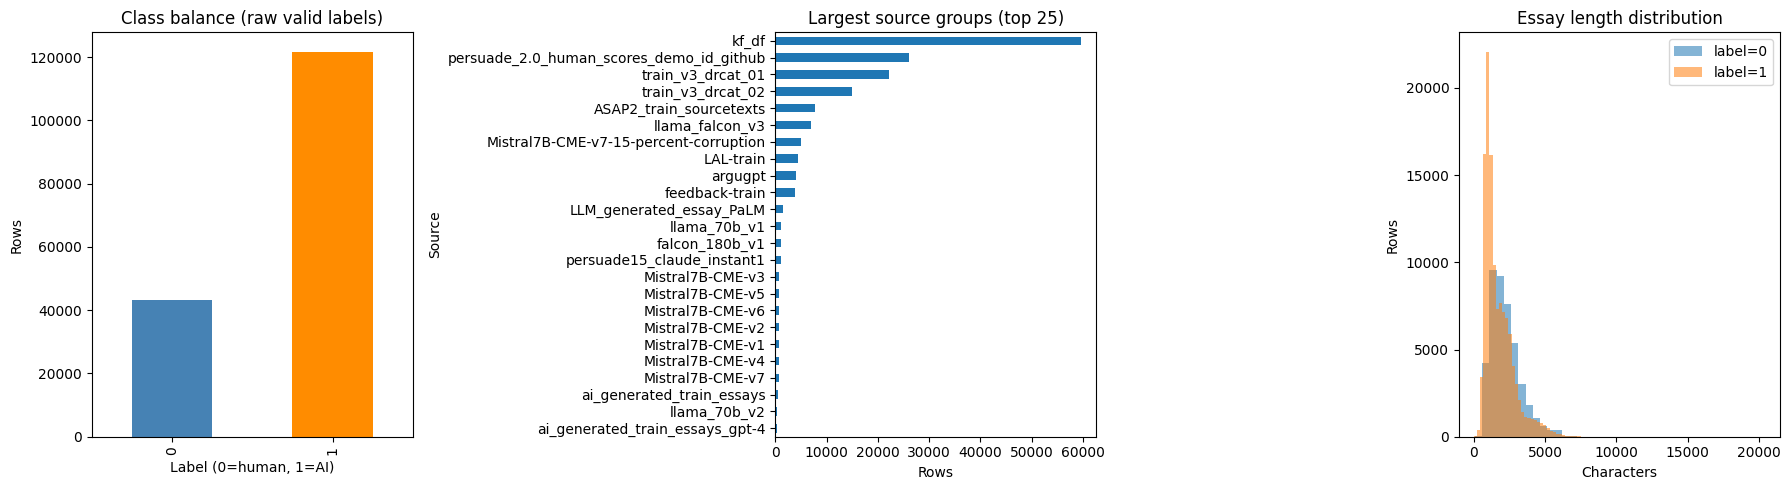

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
audit_df.loc[valid_label, "label"].value_counts().sort_index().plot.bar(ax=axes[0], color=["steelblue", "darkorange"])
axes[0].set(title="Class balance (raw valid labels)", xlabel="Label (0=human, 1=AI)", ylabel="Rows")
audit_df["source"].fillna("<missing>").value_counts().head(25).sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Largest source groups (top 25)", xlabel="Rows", ylabel="Source")
for label, group in audit_df.loc[valid_label].groupby("label"):
    group["text_length_chars"].plot.hist(bins=40, alpha=.55, ax=axes[2], label=f"label={int(label)}")
axes[2].set(title="Essay length distribution", xlabel="Characters", ylabel="Rows")
axes[2].legend()
fig.tight_layout()
display(fig)
plt.close(fig)


## 6. Data Cleaning and Splitting

Rows with missing/empty essays, invalid labels, missing source values, and normalized essays carrying contradictory labels are excluded from the modeling table. Exact NFC/trim-normalized duplicates with a single label are collapsed to one record while retaining all observed source names in `source_provenance`; the selected source remains available separately. Stable IDs are SHA-256 hashes of normalized essay text.

Existing complete split manifests are reused only when their metadata fingerprint matches the cleaned dataset and split seed. A partial or incompatible prior split stops with an explicit error rather than silently changing the shared evaluation set. Otherwise, a stratified 80/10/10 split is exported. A random split may still share prompts or source artifacts across partitions.


In [ ]:
eligible = audit_df.loc[
    valid_label
    & ~audit_df["text_empty"]
    & audit_df["source"].notna()
    & ~audit_df["normalized_text"].isin(conflicting_texts)
].copy()
eligible["label"] = eligible["label"].astype(int)
eligible["source"] = eligible["source"].astype(str)
eligible["record_id"] = eligible["normalized_text"].map(
    lambda text: hashlib.sha256(text.encode("utf-8")).hexdigest()
)
provenance = (
    eligible.groupby("normalized_text")["source"]
    .agg(lambda values: " | ".join(sorted(set(values))))
    .rename("source_provenance")
)
model_df = eligible.drop_duplicates("normalized_text", keep="first").copy()
model_df = model_df.join(provenance, on="normalized_text")
model_df = model_df[["record_id", "text_string", "label", "source", "source_provenance"]].rename(
    columns={"text_string": "text"}
).reset_index(drop=True)
if model_df["record_id"].duplicated().any():
    raise AssertionError("Stable record IDs are not unique after normalized deduplication.")

dataset_fingerprint = hashlib.sha256(
    "\n".join(sorted(model_df["record_id"])).encode("utf-8")
).hexdigest()
checkpoint_data_fingerprint = hashlib.sha256(
    model_df[["record_id", "label", "source", "source_provenance"]]
    .sort_values("record_id")
    .to_csv(index=False, lineterminator="\n")
    .encode("utf-8")
).hexdigest()
helper_module_fingerprint = hashlib.sha256((PROJECT_ROOT / "cs747_submission3.py").read_bytes()).hexdigest()
checkpoint_config = {
    "pipeline_version": 4,
    "config_mode": CONFIG_MODE,
    "active_configuration": CONFIG,
    "evaluation_protocol": EVALUATION_PROTOCOL,
    "dataset_fingerprint": dataset_fingerprint,
    "checkpoint_data_fingerprint": checkpoint_data_fingerprint,
    "helper_module_fingerprint": helper_module_fingerprint,
    "seed": SEED,
    "split_fractions": [TRAIN_FRACTION, VALIDATION_FRACTION, TEST_FRACTION],
    "bpe_vocab_size": BPE_VOCAB_SIZE,
    "bpe": {
        "unk_token": BPE_UNK_TOKEN,
        "normalizer": BPE_NORMALIZER,
        "pre_tokenizer": BPE_PRE_TOKENIZER,
        "add_prefix_space": BPE_ADD_PREFIX_SPACE,
        "special_tokens": BPE_SPECIAL_TOKENS,
    },
    "tfidf": {
        "ngram_range": TFIDF_NGRAM_RANGE,
        "min_df": TFIDF_MIN_DF,
        "max_features": TFIDF_MAX_FEATURES,
        "sublinear_tf": TFIDF_SUBLINEAR_TF,
        "lowercase": TFIDF_LOWERCASE,
        "strip_accents": TFIDF_STRIP_ACCENTS,
        "dtype": CONFIG["tfidf_dtype"],
        "analyzer": TFIDF_ANALYZER,
    },
    "sgd": SGD_SETTINGS,
    "catboost": CATBOOST_SETTINGS,
    "versions": {
        "scikit_learn": sklearn.__version__,
        "scipy": scipy.__version__,
        "catboost": __import__("catboost").__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "python": sys.version,
        "tokenizers": __import__("tokenizers").__version__,
    },
}
manifest_paths = {name: SPLIT_DIR / f"{name}.csv" for name in ("train", "validation", "test")}
metadata_path = SPLIT_DIR / "metadata.json"
present_manifests = [path.exists() for path in manifest_paths.values()]

if REUSE_EXISTING_SPLITS and any(present_manifests):
    if not all(present_manifests) or not metadata_path.is_file():
        raise FileExistsError("Found partial split manifests. Restore all manifests and metadata or move them aside explicitly.")
    split_metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    if (
        split_metadata.get("dataset_fingerprint") != dataset_fingerprint
        or split_metadata.get("seed") != SEED
        or split_metadata.get("fractions") != {"train": TRAIN_FRACTION, "validation": VALIDATION_FRACTION, "test": TEST_FRACTION}
    ):
        raise ValueError("Existing split manifests do not match this cleaned dataset and seed; refusing to reuse them.")
    train_df, val_df, test_df = (
        pd.read_csv(manifest_paths[name]) for name in ("train", "validation", "test")
    )
else:
    train_df, rest_df = train_test_split(
        model_df,
        test_size=VALIDATION_FRACTION + TEST_FRACTION,
        random_state=SEED,
        stratify=model_df["label"],
    )
    val_df, test_df = train_test_split(
        rest_df,
        test_size=TEST_FRACTION / (VALIDATION_FRACTION + TEST_FRACTION),
        random_state=SEED,
        stratify=rest_df["label"],
    )
    for name, split_df in (("train", train_df), ("validation", val_df), ("test", test_df)):
        split_df.to_csv(manifest_paths[name], index=False)
    split_metadata = {
        "seed": SEED,
        "fractions": {"train": TRAIN_FRACTION, "validation": VALIDATION_FRACTION, "test": TEST_FRACTION},
        "stratified_by": "label",
        "deduplication": "Unicode NFC + outer strip; conflicting labels excluded before split",
        "dataset_fingerprint": dataset_fingerprint,
        "record_counts": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
    }
    metadata_path.write_text(json.dumps(split_metadata, indent=2), encoding="utf-8")

split_sets = [set(frame["record_id"]) for frame in (train_df, val_df, test_df)]
if any(split_sets[i].intersection(split_sets[j]) for i in range(3) for j in range(i + 1, 3)):
    raise AssertionError("Split manifests overlap by record_id.")
split_fingerprint_hasher = hashlib.sha256()
for split_name, split_frame in zip(("train", "validation", "test"), (train_df, val_df, test_df)):
    split_fingerprint_hasher.update(split_name.encode("utf-8"))
    split_fingerprint_hasher.update(b"\n")
    for record_id in split_frame["record_id"]:
        split_fingerprint_hasher.update(str(record_id).encode("utf-8"))
        split_fingerprint_hasher.update(b"\n")
split_fingerprint = split_fingerprint_hasher.hexdigest()
previous_split_fingerprint = split_metadata.get("split_fingerprint")
if previous_split_fingerprint and previous_split_fingerprint != split_fingerprint:
    raise ValueError("Split manifests do not match their recorded fingerprint; refusing to reuse them.")
split_metadata["split_fingerprint"] = split_fingerprint
metadata_path.write_text(json.dumps(split_metadata, indent=2), encoding="utf-8")
checkpoint_config["split_fingerprint"] = split_fingerprint
checkpoint_key = hashlib.sha256(
    json.dumps(checkpoint_config, sort_keys=True).encode("utf-8")
).hexdigest()[:16]
RUN_CHECKPOINT_DIR = CHECKPOINT_ROOT / checkpoint_key
RUN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
(RUN_CHECKPOINT_DIR / "metadata.json").write_text(json.dumps(checkpoint_config, indent=2), encoding="utf-8")
del split_sets
print({name: len(frame) for name, frame in zip(("train", "validation", "test"), (train_df, val_df, test_df))})
display(pd.concat({name: frame["label"].value_counts(normalize=True) for name, frame in zip(("train", "validation", "test"), (train_df, val_df, test_df))}, axis=1).fillna(0))
del raw_df, audit_df, eligible, provenance, model_df, group_label_counts, conflicting_texts, valid_label
gc.collect()
report_memory("cleaning and shared split complete")


## 7. BPE Tokenization

Byte-pair encoding learns frequent adjacent-symbol merges from a corpus, representing common words as fewer subword units while retaining a way to segment uncommon forms. This can produce reusable subword features for stylistic text classification. No Submission #3 tokenizer settings or fitted tokenizer artifact were verified.

The adaptation below trains a ByteLevel BPE tokenizer from **training essays only** and caches it under `outputs/<mode>/checkpoints/`; the final artifact is also written under `outputs/<mode>/models/`. Checkpoints are scoped to a mode, split/data, and settings fingerprint so incompatible runs are not reused.


In [ ]:
tokenizer_path = MODEL_DIR / "bpe_tokenizer.json"
tokenizer_checkpoint_path = RUN_CHECKPOINT_DIR / "bpe_tokenizer.json"
bpe_training_time_path = RUN_CHECKPOINT_DIR / "bpe_training_time.json"
if tokenizer_checkpoint_path.is_file():
    raw_tokenizer = Tokenizer.from_file(str(tokenizer_checkpoint_path))
    bpe_training_seconds = (
        json.loads(bpe_training_time_path.read_text(encoding="utf-8"))["seconds"]
        if bpe_training_time_path.is_file()
        else None
    )
    print(f"Reused tokenizer checkpoint: {tokenizer_checkpoint_path}")
else:
    raw_tokenizer = Tokenizer(models.BPE(unk_token=BPE_UNK_TOKEN))
    if BPE_NORMALIZER == "NFC":
        raw_tokenizer.normalizer = normalizers.NFC()
    elif BPE_NORMALIZER == "NFKC":
        raw_tokenizer.normalizer = normalizers.NFKC()
    if BPE_PRE_TOKENIZER == "ByteLevel":
        raw_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=BPE_ADD_PREFIX_SPACE)
    elif BPE_PRE_TOKENIZER == "Whitespace":
        raw_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    else:
        raw_tokenizer.pre_tokenizer = pre_tokenizers.WhitespaceSplit()
    bpe_trainer = trainers.BpeTrainer(
        vocab_size=BPE_VOCAB_SIZE,
        special_tokens=BPE_SPECIAL_TOKENS,
        initial_alphabet=(pre_tokenizers.ByteLevel.alphabet() if BPE_PRE_TOKENIZER == "ByteLevel" else []),
    )
    bpe_train_start = time.perf_counter()
    raw_tokenizer.train_from_iterator((str(text) for text in train_df["text"]), trainer=bpe_trainer)
    bpe_training_seconds = time.perf_counter() - bpe_train_start
    temporary_tokenizer_path = RUN_CHECKPOINT_DIR / "bpe_tokenizer.tmp.json"
    raw_tokenizer.save(str(temporary_tokenizer_path))
    os.replace(temporary_tokenizer_path, tokenizer_checkpoint_path)
    bpe_training_time_path.write_text(
        json.dumps({"seconds": bpe_training_seconds}, indent=2), encoding="utf-8"
    )
raw_tokenizer.save(str(tokenizer_path))
bpe_word_tokenizer = BPEWordTokenizer(raw_tokenizer)
print(f"Saved training-only BPE tokenizer: {tokenizer_path}")
if bpe_training_seconds is None:
    print("BPE fit duration was not recorded for this cached tokenizer.")
else:
    print(f"BPE tokenizer fit: {bpe_training_seconds:.3f} seconds")
report_memory("BPE tokenizer ready")


## 8. TF-IDF Feature Extraction

TF-IDF weights tokens/ngrams by within-document frequency and inverse corpus frequency. Sparse word n-gram features are appropriate for lightweight text classification and preserve phrase-level evidence without constructing dense essay vectors.

The candidate 3–4 gram range comes from project notes, not a verified Submission #3 implementation. The feature cap, `min_df`, case handling, and sublinear TF are adaptations. `fit_transform` is called on training essays only; validation and test data are transformed with the frozen vocabulary/IDF values. Matrices remain CSR sparse and are saved with the fitted vectorizer for reuse after interruptions.


In [ ]:
for variable_name in ("X_train", "X_val", "X_test", "X_benchmark", "cat_model", "sgd_model"):
    globals().pop(variable_name, None)
gc.collect()
vectorizer = TfidfVectorizer(
    tokenizer=bpe_word_tokenizer,
    token_pattern=None,
    analyzer=TFIDF_ANALYZER,
    ngram_range=TFIDF_NGRAM_RANGE,
    lowercase=TFIDF_LOWERCASE,
    strip_accents=TFIDF_STRIP_ACCENTS,
    min_df=TFIDF_MIN_DF,
    max_features=TFIDF_MAX_FEATURES,
    sublinear_tf=TFIDF_SUBLINEAR_TF,
    dtype=TFIDF_DTYPE,
)
feature_checkpoint_paths = {
    "vectorizer": RUN_CHECKPOINT_DIR / "tfidf_vectorizer.joblib",
    "X_train": RUN_CHECKPOINT_DIR / "X_train.npz",
}
tfidf_training_time_path = RUN_CHECKPOINT_DIR / "tfidf_training_time.json"
if all(path.is_file() for path in feature_checkpoint_paths.values()):
    vectorizer = joblib.load(feature_checkpoint_paths["vectorizer"])
    X_train = load_npz(feature_checkpoint_paths["X_train"])
    tfidf_training_seconds = (
        json.loads(tfidf_training_time_path.read_text(encoding="utf-8"))["seconds"]
        if tfidf_training_time_path.is_file()
        else None
    )
    print(f"Reused TF-IDF feature checkpoints: {RUN_CHECKPOINT_DIR}")
else:
    check_original_memory_preflight("TF-IDF fitting")
    tfidf_train_start = time.perf_counter()
    X_train = vectorizer.fit_transform(train_df["text"].astype(str))
    tfidf_training_seconds = time.perf_counter() - tfidf_train_start
    temporary_vectorizer_path = RUN_CHECKPOINT_DIR / "tfidf_vectorizer.tmp.joblib"
    joblib.dump(vectorizer, temporary_vectorizer_path)
    os.replace(temporary_vectorizer_path, feature_checkpoint_paths["vectorizer"])
    temporary_matrix_path = RUN_CHECKPOINT_DIR / "X_train.tmp.npz"
    save_npz(temporary_matrix_path, X_train)
    os.replace(temporary_matrix_path, feature_checkpoint_paths["X_train"])
    tfidf_training_time_path.write_text(
        json.dumps({"seconds": tfidf_training_seconds}, indent=2), encoding="utf-8"
    )
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()
print("Training matrix:", X_train.shape, X_train.nnz, "nonzeros;", X_train.dtype, X_train.getformat())
print("Validation and test feature matrices will be built after training.")
if tfidf_training_seconds is None:
    print("TF-IDF fit duration was not recorded for these cached features.")
else:
    print(f"TF-IDF fit_transform: {tfidf_training_seconds:.3f} seconds")
report_memory("training TF-IDF matrix ready")


## 9. SGDClassifier

SGDClassifier optimizes a regularized linear decision function using stochastic gradient updates. The modified-Huber loss is a robust margin loss and supports `predict_proba` in scikit-learn, so the classifier can contribute probabilities to ROC-AUC and soft voting.

The exact Submission #3 SGD loss and settings were not accessible. The settings below are explicitly adaptation defaults; training time is measured independently from inference.


In [ ]:
sgd_model = SGDClassifier(**SGD_SETTINGS)
sgd_train_start = time.perf_counter()
sgd_model.fit(X_train, y_train)
sgd_training_seconds = time.perf_counter() - sgd_train_start
print(f"SGD training: {sgd_training_seconds:.3f} seconds")
report_memory("SGDClassifier fit complete")


## 10. CatBoostClassifier

CatBoost is a gradient-boosted decision-tree implementation. Here it is applied to sparse TF-IDF numeric features, not categorical text inputs. Its nonlinear splits may capture feature interactions at additional memory and CPU cost.

The published Submission #3 CatBoost iteration count, depth, learning rate, and sparse-matrix handling could not be verified. The following settings are conservative adaptations and run on CPU. CatBoost writes a native training snapshot to Drive every 60 seconds, allowing a later run with the same data and settings to resume. A completed model is also cached so later reruns can skip training.


In [ ]:
cat_model_checkpoint_path = RUN_CHECKPOINT_DIR / "catboost_model.cbm"
cat_model_timing_path = RUN_CHECKPOINT_DIR / "catboost_training_time.json"
cat_snapshot_path = RUN_CHECKPOINT_DIR / "catboost.cbsnapshot"
CATBOOST_SETTINGS["train_dir"] = str(RUN_CHECKPOINT_DIR / "catboost_info")
if cat_model_checkpoint_path.is_file():
    cat_model = CatBoostClassifier()
    cat_model.load_model(str(cat_model_checkpoint_path))
    cat_training_seconds = json.loads(cat_model_timing_path.read_text(encoding="utf-8"))["seconds"]
    if cat_snapshot_path.exists():
        cat_snapshot_path.unlink()
    print(f"Reused completed CatBoost checkpoint: {cat_model_checkpoint_path}")
else:
    check_original_memory_preflight("CatBoost training")
    cat_model = CatBoostClassifier(**CATBOOST_SETTINGS)
    resuming_catboost = cat_snapshot_path.is_file()
    if resuming_catboost:
        print(f"Resuming CatBoost from snapshot: {cat_snapshot_path}")
    cat_train_start = time.perf_counter()
    cat_model.fit(
        X_train,
        y_train,
        save_snapshot=True,
        snapshot_file=str(cat_snapshot_path),
        snapshot_interval=60,
    )
    cat_training_seconds = time.perf_counter() - cat_train_start
    temporary_model_path = RUN_CHECKPOINT_DIR / "catboost_model.tmp.cbm"
    cat_model.save_model(str(temporary_model_path))
    cat_model_timing_path.write_text(
        json.dumps({"seconds": cat_training_seconds, "resumed_from_snapshot": resuming_catboost}, indent=2),
        encoding="utf-8",
    )
    os.replace(temporary_model_path, cat_model_checkpoint_path)
    if cat_snapshot_path.exists():
        cat_snapshot_path.unlink()
    print(f"CatBoost CPU training this session: {cat_training_seconds:.3f} seconds")

report_memory("CatBoost fit or checkpoint load complete")


## 11. Submission #3 Ensemble

Soft voting combines positive-class probabilities. No original ensemble weighting or even the precise original combination rule could be verified. Therefore the notebook selects the SGD mixture weight from a predeclared grid by **validation ROC-AUC only**; the remaining weight is assigned to CatBoost. This validation-selected weight is an adaptation and is frozen before test evaluation.


In [ ]:
def positive_probability(estimator, features):
    positive_index = int(np.flatnonzero(estimator.classes_ == 1)[0])
    return estimator.predict_proba(features)[:, positive_index]


if not RUN_LOGREG_BASELINE:
    globals().pop("X_train", None)
    globals().pop("y_train", None)
    gc.collect()
validation_matrix_checkpoint_path = RUN_CHECKPOINT_DIR / "X_val.npz"
if validation_matrix_checkpoint_path.is_file():
    X_val = load_npz(validation_matrix_checkpoint_path)
else:
    X_val = vectorizer.transform(val_df["text"].astype(str))
    temporary_validation_matrix_path = RUN_CHECKPOINT_DIR / "X_val.tmp.npz"
    save_npz(temporary_validation_matrix_path, X_val)
    os.replace(temporary_validation_matrix_path, validation_matrix_checkpoint_path)
print("Validation matrix:", X_val.shape, X_val.nnz, "nonzeros")
sgd_val_probability = positive_probability(sgd_model, X_val)
cat_val_probability = positive_probability(cat_model, X_val)
ensemble_weight_candidates = np.linspace(0.0, 1.0, round(1 / ENSEMBLE_WEIGHT_STEP) + 1)
validation_weight_scores = []
for sgd_weight in ensemble_weight_candidates:
    combined = sgd_weight * sgd_val_probability + (1.0 - sgd_weight) * cat_val_probability
    validation_weight_scores.append(roc_auc_score(y_val, combined))
best_index = max(
    range(len(validation_weight_scores)),
    key=lambda index: (validation_weight_scores[index], -abs(ensemble_weight_candidates[index] - 0.5)),
)
SGD_ENSEMBLE_WEIGHT = float(ensemble_weight_candidates[best_index])
CAT_ENSEMBLE_WEIGHT = 1.0 - SGD_ENSEMBLE_WEIGHT
ensemble_configuration = {
    "method": "validation ROC-AUC grid search, 0.05 increments",
    "sgd_weight": SGD_ENSEMBLE_WEIGHT,
    "catboost_weight": CAT_ENSEMBLE_WEIGHT,
    "source_verified": False,
}
print(ensemble_configuration)


## 12. Validation Results

Validation metrics compare the two components and the selected ensemble using the same validation records. The optional Logistic Regression baseline shares the training-only BPE/TF-IDF matrix and is included only when enabled in the configuration cell. ROC-AUC is primary; threshold metrics use 0.5.


In [ ]:
def metric_record(name, truth, probability):
    prediction = (probability >= DECISION_THRESHOLD).astype(int)
    return {
        "model": name,
        "roc_auc": roc_auc_score(truth, probability),
        "accuracy": accuracy_score(truth, prediction),
        "precision": precision_score(truth, prediction, zero_division=0),
        "recall": recall_score(truth, prediction, zero_division=0),
        "f1": f1_score(truth, prediction, zero_division=0),
    }


validation_probabilities = {
    "SGDClassifier": sgd_val_probability,
    "CatBoostClassifier": cat_val_probability,
    "Submission #3 adaptation ensemble": (
        SGD_ENSEMBLE_WEIGHT * sgd_val_probability + CAT_ENSEMBLE_WEIGHT * cat_val_probability
    ),
}
if RUN_LOGREG_BASELINE:
    logreg_model = LogisticRegression(max_iter=2000, solver="liblinear", random_state=SEED)
    logreg_train_start = time.perf_counter()
    logreg_model.fit(X_train, y_train)
    logreg_training_seconds = time.perf_counter() - logreg_train_start
    validation_probabilities["Optional Logistic Regression"] = positive_probability(logreg_model, X_val)

validation_metrics = pd.DataFrame(
    [metric_record(name, y_val, probability) for name, probability in validation_probabilities.items()]
).set_index("model")
display(validation_metrics.sort_values("roc_auc", ascending=False))
display(classification_report(y_val, (validation_probabilities["Submission #3 adaptation ensemble"] >= DECISION_THRESHOLD).astype(int), output_dict=True, zero_division=0))
for variable_name in ("X_train", "X_val", "y_train", "y_val"):
    globals().pop(variable_name, None)
gc.collect()


## 13. Final Test Evaluation

After freezing the classifier settings and validation-selected ensemble weight, evaluate each model once on the same held-out test records. Do not select or adjust models based on this table. No Kaggle dummy `test_essays.csv` is used as labeled evaluation data.


In [ ]:
test_matrix_checkpoint_path = RUN_CHECKPOINT_DIR / "X_test.npz"
if test_matrix_checkpoint_path.is_file():
    X_test = load_npz(test_matrix_checkpoint_path)
else:
    X_test = vectorizer.transform(test_df["text"].astype(str))
    temporary_test_matrix_path = RUN_CHECKPOINT_DIR / "X_test.tmp.npz"
    save_npz(temporary_test_matrix_path, X_test)
    os.replace(temporary_test_matrix_path, test_matrix_checkpoint_path)
print("Test matrix:", X_test.shape, X_test.nnz, "nonzeros")
sgd_test_probability = positive_probability(sgd_model, X_test)
cat_test_probability = positive_probability(cat_model, X_test)
test_probabilities = {
    "SGDClassifier": sgd_test_probability,
    "CatBoostClassifier": cat_test_probability,
    "Submission #3 adaptation ensemble": (
        SGD_ENSEMBLE_WEIGHT * sgd_test_probability + CAT_ENSEMBLE_WEIGHT * cat_test_probability
    ),
}
if RUN_LOGREG_BASELINE:
    test_probabilities["Optional Logistic Regression"] = positive_probability(logreg_model, X_test)

test_metrics = pd.DataFrame(
    [metric_record(name, y_test, probability) for name, probability in test_probabilities.items()]
).set_index("model")
display(test_metrics)
ensemble_test_prediction = (test_probabilities["Submission #3 adaptation ensemble"] >= DECISION_THRESHOLD).astype(int)
test_confusion_matrix = pd.DataFrame(
    confusion_matrix(y_test, ensemble_test_prediction, labels=[0, 1]),
    index=["true human", "true AI"],
    columns=["pred human", "pred AI"],
)
display(test_confusion_matrix)
print(classification_report(y_test, ensemble_test_prediction, target_names=["human", "AI-generated"], zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
for name, probability in test_probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probability)
    ax.plot(false_positive_rate, true_positive_rate, label=f"{name} (AUC={roc_auc_score(y_test, probability):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Held-out test ROC curves")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_roc_curves.png", dpi=160)
display(fig)
plt.close(fig)

report_memory("held-out test evaluation complete")


## 14. CPU Benchmarking

The benchmark runs on CPU using a fixed sample of up to 2,000 test essays, warms each inference path, and repeats at least five times. End-to-end timing includes BPE tokenization, frozen TF-IDF transformation, and prediction. A bounded sample avoids a second full-test feature matrix and keeps benchmark memory use lower.


In [ ]:
BENCHMARK_BATCH_SIZE = min(BENCHMARK_MAX_ROWS, len(test_df))
benchmark_texts = test_df["text"].astype(str).head(BENCHMARK_BATCH_SIZE).tolist()

def timed_median_seconds(function, repeats=BENCHMARK_REPEATS):
    function()  # warm-up
    measurements = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        measurements.append(time.perf_counter() - start)
    return float(np.median(measurements))


def end_to_end_probability(texts, model_name):
    matrix = vectorizer.transform(texts)
    if model_name == "SGDClassifier":
        return positive_probability(sgd_model, matrix)
    if model_name == "CatBoostClassifier":
        return positive_probability(cat_model, matrix)
    if model_name == "Optional Logistic Regression":
        return positive_probability(logreg_model, matrix)
    sgd_p = positive_probability(sgd_model, matrix)
    cat_p = positive_probability(cat_model, matrix)
    return SGD_ENSEMBLE_WEIGHT * sgd_p + CAT_ENSEMBLE_WEIGHT * cat_p


tokenizer_seconds = timed_median_seconds(
    lambda: [raw_tokenizer.encode(text).tokens for text in benchmark_texts]
)
tfidf_seconds = timed_median_seconds(lambda: vectorizer.transform(benchmark_texts))
X_benchmark = X_test[:BENCHMARK_BATCH_SIZE]
sgd_prediction_seconds = timed_median_seconds(lambda: positive_probability(sgd_model, X_benchmark))
cat_prediction_seconds = timed_median_seconds(lambda: positive_probability(cat_model, X_benchmark))

benchmark_records = []
for name in test_probabilities:
    total_seconds = timed_median_seconds(lambda name=name: end_to_end_probability(benchmark_texts, name))
    benchmark_records.append(
        {
            "model": name,
            "batch_size_essays": len(benchmark_texts),
            "repeats": BENCHMARK_REPEATS,
            "median_end_to_end_seconds": total_seconds,
            "milliseconds_per_essay": 1000 * total_seconds / max(1, len(benchmark_texts)),
            "essays_per_second": len(benchmark_texts) / max(total_seconds, 1e-12),
        }
    )
benchmark_results = pd.DataFrame(benchmark_records).set_index("model")
benchmark_components = pd.Series(
    {
        "BPE tokenization only (benchmark batch)": tokenizer_seconds,
        "TF-IDF transform incl. vectorizer tokenizer (benchmark batch)": tfidf_seconds,
        "SGD prediction only (frozen CSR matrix)": sgd_prediction_seconds,
        "CatBoost prediction only (frozen CSR matrix)": cat_prediction_seconds,
        "SGD training seconds": sgd_training_seconds,
        "CatBoost training seconds (last fit session)": cat_training_seconds,
    },
    name="median_seconds_or_training_seconds",
)
display(benchmark_results)
display(benchmark_components.to_frame())
hardware = {
    "platform": platform.platform(),
    "processor": platform.processor(),
    "logical_cpu_count": os.cpu_count(),
    "memory_gib": round(psutil.virtual_memory().total / (1024**3), 2),
    "python": sys.version,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
    "catboost": __import__("catboost").__version__,
    "tokenizers": __import__("tokenizers").__version__,
}
print(json.dumps(hardware, indent=2))
del X_test, X_benchmark, benchmark_texts
gc.collect()
report_memory("CPU benchmark complete")


## 15. Model Comparison and Error Analysis

Compare validation and test metrics, per-source performance when a source has both classes, and test errors by essay-length quartile. Single-class source groups have no ROC-AUC and are reported with threshold metrics only. Error examples are truncated for inspection; treat them as qualitative evidence, not a representative sample.


In [ ]:
model_comparison = validation_metrics.add_prefix("validation_").join(test_metrics.add_prefix("test_"), how="outer")
display(model_comparison)

test_error_table = test_df[["record_id", "text", "label", "source", "source_provenance"]].copy()
test_error_table["probability_ai"] = test_probabilities["Submission #3 adaptation ensemble"]
test_error_table["prediction"] = ensemble_test_prediction
test_error_table["text_length_chars"] = test_error_table["text"].str.len()
test_error_table["length_bucket"] = pd.qcut(
    test_error_table["text_length_chars"].rank(method="first"),
    q=4,
    labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"],
)

def grouped_metrics(frame, group_column):
    records = []
    for group_value, group in frame.groupby(group_column, observed=True, dropna=False):
        truth = group["label"].to_numpy()
        probability = group["probability_ai"].to_numpy()
        prediction = group["prediction"].to_numpy()
        record = {
            group_column: group_value,
            "n": len(group),
            "accuracy": accuracy_score(truth, prediction),
            "precision": precision_score(truth, prediction, zero_division=0),
            "recall": recall_score(truth, prediction, zero_division=0),
            "f1": f1_score(truth, prediction, zero_division=0),
            "roc_auc": roc_auc_score(truth, probability) if np.unique(truth).size == 2 else np.nan,
        }
        records.append(record)
    return pd.DataFrame(records).set_index(group_column)


source_report = grouped_metrics(test_error_table, "source")
display(source_report.sort_values("n", ascending=False))
length_report = grouped_metrics(test_error_table, "length_bucket")
display(length_report)
false_positives = test_error_table.query("label == 0 and prediction == 1").sort_values("probability_ai", ascending=False)
false_negatives = test_error_table.query("label == 1 and prediction == 0").sort_values("probability_ai")
display(false_positives[["record_id", "source", "probability_ai", "text"]].head(10).assign(text=lambda frame: frame["text"].str.slice(0, 500)))
display(false_negatives[["record_id", "source", "probability_ai", "text"]].head(10).assign(text=lambda frame: frame["text"].str.slice(0, 500)))


## 16. Saving and Loading Models

The following cell saves final artifacts and results under `outputs/<mode>/`. Intermediate caches and CatBoost snapshots are kept under `outputs/<mode>/checkpoints/<run-key>`; using a different mode or settings fingerprint selects a separate checkpoint. No fake result files are included in the repository.

`joblib`/pickle artifacts can execute code when loaded; load them only from trusted sources and use compatible Python, scikit-learn, SciPy, NumPy, CatBoost, tokenizers, and helper-module versions. The helper module must remain alongside this notebook for vectorizer deserialization.


In [ ]:
joblib.dump(vectorizer, MODEL_DIR / "tfidf_vectorizer.joblib")
joblib.dump(sgd_model, MODEL_DIR / "sgd_classifier.joblib")
cat_model.save_model(str(MODEL_DIR / "catboost_classifier.cbm"))
if RUN_LOGREG_BASELINE:
    joblib.dump(logreg_model, MODEL_DIR / "logistic_regression_baseline.joblib")

configuration = {
    "config_mode": CONFIG_MODE,
    "config_status": CONFIG_STATUS,
    "active_configuration": CONFIG,
    "evaluation_protocol": EVALUATION_PROTOCOL,
    "adaptation_not_original_verified_settings": CONFIG_MODE == "low_memory",
    "checkpoint_key": checkpoint_key,
    "seed": SEED,
    "bpe": {
        "vocab_size": BPE_VOCAB_SIZE,
        "unk_token": BPE_UNK_TOKEN,
        "normalizer": BPE_NORMALIZER,
        "pre_tokenizer": BPE_PRE_TOKENIZER,
        "add_prefix_space": BPE_ADD_PREFIX_SPACE,
        "special_tokens": BPE_SPECIAL_TOKENS,
    },
    "tfidf": {
        "ngram_range": TFIDF_NGRAM_RANGE,
        "min_df": TFIDF_MIN_DF,
        "max_features": TFIDF_MAX_FEATURES,
        "lowercase": TFIDF_LOWERCASE,
        "strip_accents": TFIDF_STRIP_ACCENTS,
        "sublinear_tf": TFIDF_SUBLINEAR_TF,
        "dtype": CONFIG["tfidf_dtype"],
        "analyzer": TFIDF_ANALYZER,
    },
    "sgd": SGD_SETTINGS,
    "catboost": CATBOOST_SETTINGS,
    "ensemble": {
        **ensemble_configuration,
        "weight_step": ENSEMBLE_WEIGHT_STEP,
        "decision_threshold": DECISION_THRESHOLD,
    },
    "data_fingerprint": dataset_fingerprint,
    "split_fingerprint": split_fingerprint,
    "minimum_available_ram_gib": minimum_available_ram_gib,
    "split_counts": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
    "software": hardware,
}
(MODEL_DIR / "configuration.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")
validation_metrics.to_csv(METRICS_DIR / "validation_metrics.csv")
test_metrics.to_csv(METRICS_DIR / "test_metrics.csv")
benchmark_results.to_csv(BENCHMARK_DIR / "inference_benchmark.csv")
benchmark_components.to_csv(BENCHMARK_DIR / "benchmark_components.csv")
(BENCHMARK_DIR / "hardware.json").write_text(json.dumps(hardware, indent=2), encoding="utf-8")
model_comparison.to_csv(METRICS_DIR / "model_comparison.csv")
for split_name, frame, probabilities in (
    ("validation", val_df, validation_probabilities),
    ("test", test_df, test_probabilities),
):
    prediction_frame = frame[["record_id", "label", "source"]].copy()
    for name, values in probabilities.items():
        safe_name = name.lower().replace(" ", "_").replace("#", "submission")
        prediction_frame[f"{safe_name}_probability_ai"] = values
    prediction_frame.to_csv(PREDICTION_DIR / f"{split_name}_predictions.csv", index=False)
test_confusion_matrix.to_csv(METRICS_DIR / "test_confusion_matrix_ensemble.csv")
source_report.to_csv(METRICS_DIR / "test_source_metrics.csv")
length_report.to_csv(METRICS_DIR / "test_length_metrics.csv")
model_artifacts = [
    MODEL_DIR / "bpe_tokenizer.json",
    MODEL_DIR / "tfidf_vectorizer.joblib",
    MODEL_DIR / "sgd_classifier.joblib",
    MODEL_DIR / "catboost_classifier.cbm",
]
if RUN_LOGREG_BASELINE:
    model_artifacts.append(MODEL_DIR / "logistic_regression_baseline.joblib")
model_sizes = pd.DataFrame(
    [
        {"artifact": path.name, "size_bytes": path.stat().st_size, "size_mib": path.stat().st_size / (1024**2)}
        for path in model_artifacts
    ]
).set_index("artifact")
model_sizes.to_csv(BENCHMARK_DIR / "serialized_model_sizes.csv")
report_memory("artifacts saved")
pd.DataFrame(_MEMORY_SNAPSHOTS).to_csv(BENCHMARK_DIR / "memory_usage.csv", index=False)
display(model_sizes)
print("Saved fitted model and run outputs under", CONFIG_OUTPUT_ROOT.resolve())


def load_saved_components(model_dir=MODEL_DIR):
    """Load only trusted artifacts created with compatible dependency versions."""
    loaded_tokenizer = Tokenizer.from_file(str(model_dir / "bpe_tokenizer.json"))
    loaded_vectorizer = joblib.load(model_dir / "tfidf_vectorizer.joblib")
    loaded_sgd = joblib.load(model_dir / "sgd_classifier.joblib")
    loaded_catboost = CatBoostClassifier()
    loaded_catboost.load_model(str(model_dir / "catboost_classifier.cbm"))
    return loaded_tokenizer, loaded_vectorizer, loaded_sgd, loaded_catboost
    

## 17. Essay Prediction

`predict_essay(text)` uses the same fitted BPE-backed vectorizer and returns the adapted ensemble's estimated AI probability. It does not retrain any component. The probability is a model score and should not be interpreted as a calibrated probability unless calibration is evaluated separately.


In [ ]:
def predict_essay(text: str) -> float:
    if not isinstance(text, str) or not text.strip():
        raise ValueError("text must be a non-empty essay string")
    features = vectorizer.transform([text])
    sgd_probability = float(positive_probability(sgd_model, features)[0])
    cat_probability = float(positive_probability(cat_model, features)[0])
    return float(
        SGD_ENSEMBLE_WEIGHT * sgd_probability + CAT_ENSEMBLE_WEIGHT * cat_probability
    )


def predict_essays(texts):
    if not texts:
        return np.asarray([], dtype=float)
    if any(not isinstance(text, str) or not text.strip() for text in texts):
        raise ValueError("every item must be a non-empty essay string")
    features = vectorizer.transform(texts)
    sgd_probability = positive_probability(sgd_model, features)
    cat_probability = positive_probability(cat_model, features)
    return SGD_ENSEMBLE_WEIGHT * sgd_probability + CAT_ENSEMBLE_WEIGHT * cat_probability


# Example after running the training cells:
# probability_ai = predict_essay("Paste an essay here.")


## 18. Reproduction Limitations and Research Discussion

### Verification and methodological limits

- The Kaggle write-up body, author, linked source implementation, exact feature settings, model hyperparameters, ensemble weights, and model artifacts were not accessible for verification. The title and placement are verified; implementation settings here are adaptations based on project notes.
- No fitted Submission #3 artifacts are included. BPE, TF-IDF, SGD, and CatBoost fit from the team's training split when the notebook is run. Classical models are refit here; they are not pretrained language models.
- The original competition may have used transductive fitting or different competition data; this could not be confirmed for Submission #3. This notebook never fits BPE or TF-IDF on validation/test data.
- The project dataset is independently assembled and may contain source, prompt, or generator fingerprints. Random stratification does not prove generalization to unseen sources or generation systems. Group-held-out evaluation requires reliable prompt or document-group identifiers.
- Historical leaderboard results are not reproduced or asserted. Test estimates can be biased by duplicated prompts, source/class confounding, domain shift, and annotation artifacts. AI-text detectors can produce false accusations and should not be treated as definitive authorship evidence.
- CatBoost sparse-CSR compatibility, practical memory consumption, dependency compatibility, and execution time remain unverified until the user runs the notebook in their environment.

### Discussion after running

Use the generated validation/test tables and benchmark files to discuss: (1) whether the ensemble improves on each component and optional Logistic Regression, (2) whether gains justify added CPU latency, (3) which sources and length buckets are hardest, (4) how many errors arise from source-specific artifacts, (5) whether conclusions extend to unseen generators, and (6) how this protocol differs from the original competition. Do not select hyperparameters based on the test results.


## 19. References

1. Kaggle, **[3rd Place Efficiency Prize] Simple Solution**: [original write-up](https://www.kaggle.com/competitions/llm-detect-ai-generated-text/writeups/beat-tfidf-3rd-place-efficiency-prize-simple-solut). Article content/author attribution was not accessible to verify beyond the page title.
2. Kaggle, **LLM - Detect AI Generated Text**: [competition page](https://www.kaggle.com/competitions/llm-detect-ai-generated-text/).
3. Project team, **CS747data.csv archive**: [shared archive](https://drive.google.com/file/d/1Mha2tWMZ77C5_dJA7U_vIb_ac_fWAdgI/view?usp=sharing).
4. Hugging Face, [Tokenizers documentation](https://huggingface.co/docs/tokenizers/).
5. scikit-learn, [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [SGDClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html), and [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
6. CatBoost, [Classifier documentation](https://catboost.ai/en/docs/concepts/python-reference_catboostclassifier).
7. Local verification/adaptation record: [references/submission3_reproduction_notes.md](references/submission3_reproduction_notes.md).


## 20. Copy-Paste Results Summary

After completing the notebook, this section writes a consolidated JSON report with evaluation metrics, split counts, efficiency results, training timings, artifact sizes, reproducibility details, and output paths. Values unavailable from reused older checkpoints are labeled as not recorded rather than estimated.

In [ ]:
split_class_counts = {
    split_name: {
        "rows": int(len(frame)),
        "human_label_0": int((frame["label"] == 0).sum()),
        "ai_generated_label_1": int((frame["label"] == 1).sum()),
    }
    for split_name, frame in (("train", train_df), ("validation", val_df), ("test", test_df))
}
cat_timing_record = (
    json.loads(cat_model_timing_path.read_text(encoding="utf-8"))
    if cat_model_timing_path.is_file()
    else {}
)
training_components = {
    "BPE tokenizer fit seconds": bpe_training_seconds,
    "TF-IDF fit_transform seconds": tfidf_training_seconds,
    "SGDClassifier fit seconds": sgd_training_seconds,
    "CatBoost fit seconds": cat_training_seconds,
}
if RUN_LOGREG_BASELINE:
    training_components["Optional Logistic Regression fit seconds"] = logreg_training_seconds
all_fit_times_recorded = all(value is not None for value in training_components.values())
catboost_resumed = bool(cat_timing_record.get("resumed_from_snapshot", False))
complete_fit_duration = (
    sum(float(value) for value in training_components.values())
    if all_fit_times_recorded and not catboost_resumed
    else None
)
artifact_sizes = model_sizes[["size_bytes", "size_mib"]].to_dict(orient="index")
pipeline_size_bytes = int(model_sizes["size_bytes"].sum())
artifact_sizes["TOTAL SAVED PIPELINE"] = {
    "size_bytes": pipeline_size_bytes,
    "size_mib": pipeline_size_bytes / (1024**2),
    "size_mb": pipeline_size_bytes / 1_000_000,
}
difficult_sources = (
    source_report.dropna(subset=["roc_auc"])
    .sort_values("roc_auc", ascending=True)
    .head(5)
    .reset_index()
    .to_dict(orient="records")
)
doc_fill_summary = {
    "model": {
        "name": "Submission #3 adaptation ensemble",
        "configuration_mode": CONFIG_MODE,
        "configuration_status": CONFIG_STATUS,
        "method": "BPE-tokenized word TF-IDF with SGDClassifier and CatBoost soft-voting ensemble",
        "ensemble_weights": ensemble_configuration,
        "ensemble_method": "validation ROC-AUC grid search; settings are adaptation protocol, not verified original weights",
        "fitting": "Components are fit from the training split; compatible run checkpoints may be reused on reruns. No pretrained language model is used.",
        "decision_threshold": DECISION_THRESHOLD,
        "original_writeup": "https://www.kaggle.com/competitions/llm-detect-ai-generated-text/writeups/beat-tfidf-3rd-place-efficiency-prize-simple-solut",
        "original_leaderboard_roc_auc": "Not measured locally or independently verified; enter only from a verified source.",
    },
    "dataset_and_reproducibility": {
        "dataset_fingerprint_sha256": dataset_fingerprint,
        "checkpoint_key": checkpoint_key,
        "split_fingerprint": split_fingerprint,
        "seed": SEED,
        "split_counts_by_class": split_class_counts,
        "configuration": configuration,
    },
    "evaluation": {
        "validation_metrics": validation_metrics.to_dict(orient="index"),
        "test_metrics": test_metrics.to_dict(orient="index"),
        "test_ensemble_confusion_matrix": {
            "true_labels": test_confusion_matrix.index.tolist(),
            "predicted_labels": test_confusion_matrix.columns.tolist(),
            "counts": test_confusion_matrix.to_numpy().astype(int).tolist(),
        },
        "test_ensemble_classification_report": classification_report(
            y_test,
            ensemble_test_prediction,
            target_names=["human", "AI-generated"],
            output_dict=True,
            zero_division=0,
        ),
        "test_false_positive_count": int(len(false_positives)),
        "test_false_negative_count": int(len(false_negatives)),
        "lowest_auc_test_sources_top_5": difficult_sources,
        "test_source_metrics": source_report.reset_index().to_dict(orient="records"),
        "test_length_bucket_metrics": length_report.reset_index().to_dict(orient="records"),
        "threshold_note": f"Accuracy, precision, recall, F1, and confusion matrix use threshold {DECISION_THRESHOLD}; ROC-AUC uses continuous scores.",
    },
    "efficiency": {
        "inference_benchmark": benchmark_results.rename_axis("model").reset_index().to_dict(orient="records"),
        "benchmark_components_seconds": benchmark_components.to_dict(),
        "protocol": {
            "device": "CPU",
            "batch_size_essays": int(BENCHMARK_BATCH_SIZE),
            "repeats_after_warmup": int(BENCHMARK_REPEATS),
            "reported_statistic": "median end-to-end inference time including TF-IDF transformation",
            "catboost_thread_count": CATBOOST_SETTINGS.get("thread_count"),
        },
        "serialized_artifact_sizes": artifact_sizes,
        "total_saved_pipeline_size_mb": pipeline_size_bytes / 1_000_000,
        "total_saved_pipeline_size_mib": pipeline_size_bytes / (1024**2),
    },
    "training_duration": {
        "fit_stage_seconds": training_components,
        "sum_seconds_if_complete": complete_fit_duration,
        "catboost_resumed_from_snapshot": catboost_resumed,
        "note": "Durations cover fit stages, not data loading, evaluation, or serialization. Cached BPE/TF-IDF durations are reused when recorded; missing checkpoint timing is null. A resumed CatBoost duration covers only its last fit session, so no complete total is reported.",
    },
    "memory": {
        "peak_process_rss_bytes": max((item["peak_process_rss_bytes"] for item in _MEMORY_SNAPSHOTS), default=None),
        "peak_process_rss_gib": max((item["peak_process_rss_gib"] for item in _MEMORY_SNAPSHOTS), default=None),
        "stage_snapshots": _MEMORY_SNAPSHOTS,
        "note": "Peak process RSS is a process high-water mark; available system RAM is sampled at each stage.",
    },
    "hardware_and_software": hardware,
    "artifacts": {
        "output_root": str(OUTPUT_ROOT.resolve()),
        "configuration_output_root": str(CONFIG_OUTPUT_ROOT.resolve()),
        "model_directory": str(MODEL_DIR.resolve()),
        "summary_json": str((METRICS_DIR / "doc_fill_summary.json").resolve()),
        "metrics_directory": str(METRICS_DIR.resolve()),
        "benchmark_directory": str(BENCHMARK_DIR.resolve()),
        "prediction_directory": str(PREDICTION_DIR.resolve()),
        "validation_metrics_csv": str((METRICS_DIR / "validation_metrics.csv").resolve()),
        "test_metrics_csv": str((METRICS_DIR / "test_metrics.csv").resolve()),
        "confusion_matrix_csv": str((METRICS_DIR / "test_confusion_matrix_ensemble.csv").resolve()),
        "inference_benchmark_csv": str((BENCHMARK_DIR / "inference_benchmark.csv").resolve()),
        "memory_usage_csv": str((BENCHMARK_DIR / "memory_usage.csv").resolve()),
        "test_roc_curve_png": str((FIGURE_DIR / "test_roc_curves.png").resolve()),
        "prediction_files": [
            str((PREDICTION_DIR / "validation_predictions.csv").resolve()),
            str((PREDICTION_DIR / "test_predictions.csv").resolve()),
        ],
    },
    "interpretation": "The report consolidates measurements; selecting the best performance-efficiency trade-off and discussing methodological limitations require human interpretation.",
}
def json_safe(value):
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return str(value)


doc_fill_summary_path = METRICS_DIR / "doc_fill_summary.json"
doc_fill_summary_json = json.dumps(json_safe(doc_fill_summary), indent=2, allow_nan=False)
doc_fill_summary_path.write_text(doc_fill_summary_json, encoding="utf-8")
print("Document-ready evaluation summary:")
print(doc_fill_summary_json)
print(f"Saved JSON summary to: {doc_fill_summary_path}")


## 21. Original vs. Memory-Optimized Model Comparison

The comparison reads each mode's saved `metrics/doc_fill_summary.json`; it does not load models, rerun inference, or invent missing results. It reports pending configurations explicitly and saves a table, measured deltas, and performance-efficiency figures under `outputs/comparison/`.

### Interpretation and manual workflow

- Lower TF-IDF feature limits can reduce feature memory and training work, but may change ROC-AUC. CatBoost iteration count and tree depth affect model capacity; their effects on training and inference time must be measured separately rather than assumed proportional.
- Compare the ensemble with SGDClassifier in the saved per-model results to determine whether the ensemble helped on this dataset. Prefer CPU inference settings based on measured latency, throughput, memory, and held-out ROC-AUC; do not infer a winner before both runs complete.
- Run 1: leave `CONFIG_MODE = "low_memory"` in the configuration cell and run the notebook top to bottom. Results are saved under `outputs/low_memory/`.
- Run 2: original settings are currently blocked because the Kaggle write-up body/source was not accessible and the exact hyperparameters are unverified. Only after supplying verified original values in `CONFIG_PROFILES["original"]["settings"]`, restart the kernel, select `CONFIG_MODE = "original"`, and run top to bottom. Results will be saved under `outputs/original/`.
- After both result files exist, run this section's code cell. It also works in a fresh kernel without loading models; on Colab, mount Drive first and run the cell from the project directory (or with the project path available).


In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

comparison_candidates = []
if "PROJECT_ROOT" in globals():
    comparison_candidates.append(Path(PROJECT_ROOT))
comparison_candidates.extend([
    Path.cwd(),
    Path("/content/drive/MyDrive/DeepLearning_progress"),
])
comparison_project_root = next(
    (
        candidate for candidate in comparison_candidates
        if (candidate / "cs747_submission3.py").is_file()
        or (candidate / "data" / "CS747data.csv").is_file()
        or (candidate / "outputs" / "low_memory" / "metrics").is_dir()
        or (candidate / "outputs" / "original" / "metrics").is_dir()
    ),
    None,
)
if comparison_project_root is None:
    raise FileNotFoundError(
        "Could not locate the project outputs directory. Set PROJECT_ROOT, change to the project folder, "
        "or mount Drive at /content/drive/MyDrive/DeepLearning_progress."
    )
comparison_output_root = comparison_project_root / "outputs"
comparison_dir = comparison_output_root / "comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

mode_summaries = {}
for mode in ("original", "low_memory"):
    summary_path = comparison_output_root / mode / "metrics" / "doc_fill_summary.json"
    mode_summaries[mode] = json.loads(summary_path.read_text(encoding="utf-8")) if summary_path.is_file() else None

print("Saved evaluation metrics (all available validation/test models and diagnostics):")
for mode, summary in mode_summaries.items():
    print(f"\n=== {mode} ===")
    if summary is None:
        print("Pending: this configuration has no completed saved summary.")
        continue
    print(json.dumps(summary.get("evaluation", {}), indent=2, default=lambda value: value.item() if isinstance(value, np.generic) else str(value)))
    print("Inference benchmark:")
    print(json.dumps(summary.get("efficiency", {}).get("inference_benchmark", []), indent=2))
    print("Memory summary:")
    print(json.dumps(summary.get("memory", {}), indent=2))
    print("Training-duration summary:")
    print(json.dumps(summary.get("training_duration", {}), indent=2))

ensemble_name = "Submission #3 adaptation ensemble"
comparison_values = {}
for mode, summary in mode_summaries.items():
    if summary is None:
        comparison_values[mode] = {}
        continue
    evaluation = summary.get("evaluation", {})
    ensemble_metrics = evaluation.get("test_metrics", {}).get(ensemble_name, {})
    benchmark_rows = summary.get("efficiency", {}).get("inference_benchmark", [])
    ensemble_benchmark = next((row for row in benchmark_rows if row.get("model") == ensemble_name), {})
    comparison_values[mode] = {
        "Test ROC-AUC": ensemble_metrics.get("roc_auc"),
        "Test accuracy": ensemble_metrics.get("accuracy"),
        "Test precision": ensemble_metrics.get("precision"),
        "Test recall": ensemble_metrics.get("recall"),
        "Test F1-score": ensemble_metrics.get("f1"),
        "CPU latency (ms/essay)": ensemble_benchmark.get("milliseconds_per_essay"),
        "Throughput (essays/second)": ensemble_benchmark.get("essays_per_second"),
        "Saved pipeline size (MB)": summary.get("efficiency", {}).get("total_saved_pipeline_size_mb"),
        "Peak process RSS (GiB)": summary.get("memory", {}).get("peak_process_rss_gib"),
        "Complete fit-stage time (seconds)": summary.get("training_duration", {}).get("sum_seconds_if_complete"),
    }

comparison_table = pd.DataFrame(comparison_values)
comparison_table.to_csv(comparison_dir / "original_vs_low_memory_metrics.csv")
display(comparison_table.astype(object).where(comparison_table.notna(), "Pending"))

def relative_percent_change(original, low_memory):
    if original is None or low_memory is None or original == 0:
        return None
    return 100 * (low_memory - original) / original

def relative_reduction_percent(original, low_memory):
    if original is None or low_memory is None or original == 0:
        return None
    return 100 * (original - low_memory) / original

original_values = comparison_values.get("original", {})
low_memory_values = comparison_values.get("low_memory", {})
deltas = {
    "absolute ROC-AUC change (low_memory - original)": (
        low_memory_values.get("Test ROC-AUC") - original_values.get("Test ROC-AUC")
        if low_memory_values.get("Test ROC-AUC") is not None and original_values.get("Test ROC-AUC") is not None
        else None
    ),
    "relative CPU latency change percent (low_memory vs original)": relative_percent_change(
        original_values.get("CPU latency (ms/essay)"), low_memory_values.get("CPU latency (ms/essay)")
    ),
    "relative peak-RAM reduction percent": relative_reduction_percent(
        original_values.get("Peak process RSS (GiB)"), low_memory_values.get("Peak process RSS (GiB)")
    ),
    "relative saved-model-size reduction percent": relative_reduction_percent(
        original_values.get("Saved pipeline size (MB)"), low_memory_values.get("Saved pipeline size (MB)")
    ),
    "relative throughput improvement percent": relative_percent_change(
        original_values.get("Throughput (essays/second)"), low_memory_values.get("Throughput (essays/second)")
    ),
}
(comparison_dir / "comparison_deltas.json").write_text(json.dumps(deltas, indent=2), encoding="utf-8")
print("Measured changes (null means one or both runs are pending or not measurable):")
print(json.dumps(deltas, indent=2))

plot_points = {
    mode: values for mode, values in comparison_values.items()
    if values.get("Test ROC-AUC") is not None
}
if plot_points:
    fig, ax = plt.subplots(figsize=(7, 5))
    for mode, values in plot_points.items():
        latency = values.get("CPU latency (ms/essay)")
        if latency is not None:
            ax.scatter(latency, values["Test ROC-AUC"], label=mode)
            ax.annotate(mode, (latency, values["Test ROC-AUC"]))
    ax.set(xlabel="Median CPU latency (ms/essay)", ylabel="Test ROC-AUC", title="Detection performance vs. CPU latency")
    ax.legend()
    fig.tight_layout()
    fig.savefig(comparison_dir / "roc_auc_vs_cpu_latency.png", dpi=160)
    display(fig)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 5))
    for mode, values in plot_points.items():
        peak_ram = values.get("Peak process RSS (GiB)")
        if peak_ram is not None:
            ax.scatter(peak_ram, values["Test ROC-AUC"], label=mode)
            ax.annotate(mode, (peak_ram, values["Test ROC-AUC"]))
    ax.set(xlabel="Peak process RSS (GiB)", ylabel="Test ROC-AUC", title="Detection performance vs. peak RAM")
    ax.legend()
    fig.tight_layout()
    fig.savefig(comparison_dir / "roc_auc_vs_peak_ram.png", dpi=160)
    display(fig)
    plt.close(fig)
else:
    print("Comparison figures will be generated after at least one configuration has saved metrics.")
print(f"Saved comparison outputs to: {comparison_dir.resolve()}")
